# 03 - Positive-control diagnostic, directional estimand, larger sample

**Why this notebook.** Notebook 02 showed:
- the absolute-change estimand is weak and not specific (Qwen-7B looked 'significant' without moving toward the right answer);
- the **directional, time-matched estimand R_dir** detected the positive control (0.052 [0.015, 0.090]) and was ~0 for both Qwen models;
- the positive control's AUC was only 0.63 - either text-mined label flips are noisy, or preprocessing is wrong.

**What this notebook does**
1. **Diagnostic:** DenseNet AUC on ~1,000 random NIH images (not selected as flips). AUC around 0.8 or more on random images but 0.63 on flip images means the selection of noisy flips is the problem (all R values attenuated). AUC near 0.63 on random images too means a preprocessing bug.
2. **Primary estimand R_dir** = D_flip - D_ctrl, where D_flip = (p_flip - p_anchor) x (y_flip - y_anchor) and D_ctrl is the same signed change on a same-label pair of the same patient at the same time offset. Absolute S/N/R kept as secondary.
3. **Larger sample:** 1,500 balanced anchors for the positive control; a balanced subset (default 800) for the slower VLMs, so all models can be compared on shared anchors.
4. **MedGemma retry** with full error output.

**Settings:** NIH Chest X-rays input (Datasets tab), **GPU T4 x2**, Internet on, Kaggle secret **HF_TOKEN** (after accepting the MedGemma licence on Hugging Face).
Runtime: DenseNet a few minutes; each VLM roughly 1-2 h on 800 anchors. Reduce `N_VLM` if your GPU quota is short.

In [1]:
!pip -q install torchxrayvision
# If a VLM fails with an unknown-architecture error:  !pip -q install -U transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 62.2 MB/s eta 0:00:00


In [2]:
%%writefile pilot_lib.py
# ---- Pair construction and estimation (no model code) ----
import numpy as np
import pandas as pd

NIH_FINDINGS = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Effusion", "Emphysema",
                "Fibrosis", "Hernia", "Infiltration", "Mass", "Nodule", "Pleural_Thickening",
                "Pneumonia", "Pneumothorax"]


def add_label(df, finding):
    out = df.copy()
    out["label"] = out["Finding Labels"].str.split("|").apply(lambda L: int(finding in L))
    return out


def build_anchor_triples(df, finding, same_view=True, max_anchors_per_patient=2, seed=0,
                         match_gap=False, gap_tol=1, control="anchor"):
    """For each anchor image A, find in the SAME patient:
       flip partner  F: another study with the opposite label for `finding` (should change the answer)
       same partner  S: another study with the same label (should not change the answer)
    Partners are the nearest follow-ups (smallest |follow-up gap|) and share A's view if same_view.
    Using a same-patient, different-day image as the control means both arms carry the same kind
    of nuisance change (positioning, exposure, time), so R = S - N subtracts it."""
    rng = np.random.default_rng(seed)
    d = add_label(df, finding)
    key = ["Patient ID", "View Position"] if same_view else ["Patient ID"]
    d = d[d.groupby(key)["Image Index"].transform("size") >= 3]
    rows = []
    for k, g in d.groupby(key):
        pid = k[0] if isinstance(k, tuple) else k
        img = g["Image Index"].to_numpy(); lab = g["label"].to_numpy()
        fu = g["Follow-up #"].to_numpy(); view = g["View Position"].to_numpy()
        if lab.min() == lab.max():
            continue
        anchors = []
        for i in range(len(g)):
            other = np.arange(len(g)) != i
            fl = np.where(other & (lab != lab[i]))[0]
            sm = np.where(other & (lab == lab[i]))[0]
            if len(fl) == 0 or len(sm) == 0:
                continue
            f = fl[np.abs(fu[fl] - fu[i]).argmin()]
            if control == "pair":
                # control = a same-label PAIR (u, v) of this patient with EXACTLY the flip pair's signed
                # follow-up gap; prefer the anchor's status, then the pair closest in time to the anchor
                k = fu[f] - fu[i]
                best = None
                for u in range(len(g)):
                    for v in np.where((fu - fu[u]) == k)[0]:
                        if v == u or lab[u] != lab[v] or {u, v} == {i, f}:
                            continue
                        key_ = (lab[u] != lab[i], abs(fu[u] - fu[i]))
                        if best is None or key_ < best[0]:
                            best = (key_, u, v)
                if best is None:
                    continue
                _, u, v = best
                anchors.append(dict(patient=pid, view=view[i], img_a=img[i], lab_a=int(lab[i]),
                                    img_f=img[f], lab_f=int(lab[f]), img_s1=img[u], img_s=img[v],
                                    lab_s=int(lab[v]), gap_f=int(abs(k)), gap_s=int(abs(fu[v] - fu[u])),
                                    sgap_f=int(k), sgap_s=int(fu[v] - fu[u])))
                continue
            if match_gap:
                # control at the same signed time offset as the flip partner (same direction in time,
                # similar distance), so time/positioning drift is equal in both arms
                off = (fu[sm] - fu[i]) - (fu[f] - fu[i])
                s = sm[np.abs(off).argmin()]
                if abs((fu[s] - fu[i]) - (fu[f] - fu[i])) > gap_tol:
                    continue
            else:
                s = sm[np.abs(fu[sm] - fu[i]).argmin()]
            anchors.append(dict(patient=pid, view=view[i], img_a=img[i], lab_a=int(lab[i]),
                                img_f=img[f], lab_f=int(lab[f]), img_s=img[s], lab_s=int(lab[s]),
                                gap_f=int(abs(fu[f] - fu[i])), gap_s=int(abs(fu[s] - fu[i])),
                                sgap_f=int(fu[f] - fu[i]), sgap_s=int(fu[s] - fu[i])))
        if anchors:
            idx = rng.permutation(len(anchors))[:max_anchors_per_patient]
            rows += [anchors[i] for i in idx]
    if same_view and rows:   # a patient can appear in two view groups: keep the per-patient cap
        t = pd.DataFrame(rows).sample(frac=1, random_state=seed)
        rows = t.groupby("patient").head(max_anchors_per_patient).to_dict("records")
    t = pd.DataFrame(rows)
    if len(t):
        t["direction"] = np.where(t["lab_a"] == 0, "absent->present", "present->absent")
    return t


def flip_counts(df, findings=NIH_FINDINGS, same_view=True):
    """Feasibility table: per finding, patients with a within-patient flip (each direction),
    and anchors with BOTH a flip and a same-label partner."""
    out = []
    key = ["Patient ID", "View Position"] if same_view else ["Patient ID"]
    for f in findings:
        d = add_label(df, f).sort_values(key + ["Follow-up #"])
        diff = d.groupby(key)["label"].diff()
        up = d.loc[diff == 1, "Patient ID"].nunique()      # consecutive studies, same view
        down = d.loc[diff == -1, "Patient ID"].nunique()
        trip = build_anchor_triples(df, f, same_view=same_view, max_anchors_per_patient=1)
        out.append(dict(finding=f, patients_absent_to_present=up, patients_present_to_absent=down,
                        patients_with_flip_and_same_partner=len(trip),
                        of_which_anchor_absent=int((trip["lab_a"] == 0).sum()) if len(trip) else 0,
                        of_which_anchor_present=int((trip["lab_a"] == 1).sum()) if len(trip) else 0))
    return pd.DataFrame(out)


def sample_balanced(trip, n, seed=0):
    """Balance the two flip directions so a yes/no bias cannot masquerade as reliance."""
    parts = [g.sample(min(len(g), n // 2), random_state=seed) for _, g in trip.groupby("direction")]
    return pd.concat(parts).reset_index(drop=True)


def _logit(p, eps=1e-4):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def item_quantities(res, scale="prob"):
    """res needs p_a, p_f, p_s (P(yes) under anchor, flip partner, same-label partner).
    scale='prob' uses probability differences; scale='logit' uses log-odds differences
    (less compressed near 0/1, makes models with different calibration more comparable)."""
    r = res.copy()
    if scale == "logit":
        for c in ["p_a", "p_f", "p_s", "p_s1"]:
            if c in r:
                r[c] = _logit(r[c].to_numpy())
    r["d_change"] = (r["p_f"] - r["p_a"]).abs()          # sensitivity (should be large)
    ref = r["p_s1"] if "p_s1" in r else r["p_a"]          # pair control: |p(C2) - p(C1)|
    r["d_preserve"] = (r["p_s"] - ref).abs()             # nuisance sensitivity (should be small)
    r["R"] = r["d_change"] - r["d_preserve"]             # evidence-specific reliance
    dy = r["lab_f"] - r["lab_a"]                          # +1 absent->present, -1 present->absent
    r["signed_dir"] = (r["p_f"] - r["p_a"]) * dy          # >0 = moved the right way
    # Directional, time-matched estimand (primary): change toward the new label on the flip pair,
    # minus the same signed change on a same-label pair of the same patient at the same time offset
    r["D_flip"] = r["signed_dir"]
    r["D_ctrl"] = (r["p_s"] - ref) * dy
    r["R_dir"] = r["D_flip"] - r["D_ctrl"]
    return r


DEFAULT_COLS = ("D_flip", "D_ctrl", "R_dir", "d_change", "d_preserve", "R")


def cluster_bootstrap(r, cols=DEFAULT_COLS, B=2000, seed=0, by="patient"):
    """Point estimates (mean of patient means) and percentile CIs resampling PATIENTS."""
    rng = np.random.default_rng(seed)
    cols = [c for c in cols if c in r]
    pm = r.groupby(by)[cols].mean()
    est = pm.mean()
    boots = np.empty((B, len(cols)))
    n = len(pm)
    arr = pm.to_numpy()
    for b in range(B):
        boots[b] = arr[rng.integers(0, n, n)].mean(axis=0)
    lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
    p_le0 = (boots <= 0).mean(axis=0)               # one-sided bootstrap p for H0: quantity <= 0
    return pd.DataFrame({"estimate": est.values, "ci_low": lo, "ci_high": hi, "p_one_sided": p_le0,
                         "n_patients": n}, index=cols)


def summarize(r, B=2000, seed=0):
    from scipy.stats import binomtest
    overall = cluster_bootstrap(r, B=B, seed=seed)
    by_dir = {k: cluster_bootstrap(g, B=B, seed=seed) for k, g in r.groupby("direction")}
    pm = r.groupby("patient")["R_dir" if "R_dir" in r else "R"].mean()
    nz = pm[pm != 0]
    sign_p = binomtest(int((nz > 0).sum()), len(nz), 0.5, alternative="greater").pvalue if len(nz) else np.nan
    acc = ((r["p_a"] > 0.5).astype(int) == r["lab_a"]).mean()
    return overall, by_dir, sign_p, acc


def paired_difference(r1, r2, col="R", B=4000, seed=0):
    """Difference in a per-item quantity between two models scored on the SAME anchors,
    with a patient-level paired bootstrap. Returns estimate, CI and two-sided bootstrap p."""
    rng = np.random.default_rng(seed)
    a = r1.groupby("patient")[col].mean(); b = r2.groupby("patient")[col].mean()
    a, b = a.align(b, join="inner")
    d = (a - b).to_numpy(); n = len(d)
    boots = np.array([d[rng.integers(0, n, n)].mean() for _ in range(B)])
    p = 2 * min((boots <= 0).mean(), (boots >= 0).mean())
    return dict(estimate=d.mean(), ci_low=np.percentile(boots, 2.5), ci_high=np.percentile(boots, 97.5),
                p_boot=min(p, 1.0), n_patients=n)


def gap_balance(t):
    """Check that the control is time-matched to the flip partner."""
    return pd.Series({"mean_gap_flip": t["gap_f"].mean(), "mean_gap_same": t["gap_s"].mean(),
                      "share_same_time_direction": (np.sign(t["sgap_f"]) == np.sign(t["sgap_s"])).mean()
                      if "sgap_f" in t else np.nan})


Writing pilot_lib.py


In [3]:
import os, glob, json, time, gc, traceback
import numpy as np, pandas as pd
from pilot_lib import *

FINDING = "Effusion"
QUESTION = "Is there a pleural effusion in this chest X-ray? Answer yes or no."
N_ANCHORS = 1500        # positive control
N_VLM = 800             # balanced subset scored by the VLMs
N_RANDOM = 1000         # diagnostic: random NIH images (half positive)
SEED = 0
OUT = "/kaggle/working"
MAX_PIXELS = 512 * 28 * 28
MODELS = [  # name, kind, dtype, which anchors
    ("xrv-densenet121-res224-chex", "xrv", None, "all"),
    ("Qwen/Qwen2.5-VL-7B-Instruct", "vlm", "float16", "vlm"),
    ("google/medgemma-4b-it", "vlm", "float32", "vlm"),
]

## 1. NIH metadata and images

In [4]:
def find_file(name, top="/kaggle/input"):
    for r, dirs, files in os.walk(top, followlinks=True):
        if name in files:
            return os.path.join(r, name)
        dirs[:] = [d for d in dirs if not d.startswith("images")]
    return None

print("Attached inputs:", os.listdir("/kaggle/input"))
meta = find_file("Data_Entry_2017.csv") or find_file("Data_Entry_2017_v2020.csv")
assert meta, "Attach the NIH Chest X-rays dataset (Add Input -> Datasets -> nih-chest-xrays/data)"
df = pd.read_csv(meta); df.columns = [c.strip() for c in df.columns]
root = os.path.dirname(meta)
img_paths = {os.path.basename(p): p for p in glob.glob(f"{root}/**/*.png", recursive=True)}
print(df.shape, "|", len(img_paths), "images")
assert img_paths, "Images not found - the dataset must be attached, not only the CSV"

Attached inputs: ['datasets']
(112120, 12) | 112120 images


## 2. Anchors (time-matched pair controls) and the random diagnostic set

In [5]:
trip = build_anchor_triples(df, FINDING, same_view=True, max_anchors_per_patient=1, seed=SEED, control="pair")
print(len(trip), "anchors available |", trip["direction"].value_counts().to_dict())
cols = ["img_a", "img_f", "img_s1", "img_s"]
trip = trip[trip[cols].isin(list(img_paths)).all(axis=1)]
samp = sample_balanced(trip, N_ANCHORS, seed=SEED).reset_index(drop=True)
samp["vlm"] = samp.index.isin(sample_balanced(samp.assign(_i=samp.index), N_VLM, seed=SEED + 1)["_i"])
print("sampled:", len(samp), "|", samp["direction"].value_counts().to_dict(), "| VLM subset:", int(samp["vlm"].sum()))
print("gap balance:", gap_balance(samp).round(2).to_dict())
samp.to_csv(f"{OUT}/triples03_{FINDING}.csv", index=False)

def label_table(s):
    return pd.concat([s[["img_a", "lab_a"]].set_axis(["img", "lab"], axis=1),
                      s[["img_f", "lab_f"]].set_axis(["img", "lab"], axis=1),
                      s[["img_s1", "lab_s"]].set_axis(["img", "lab"], axis=1),
                      s[["img_s", "lab_s"]].set_axis(["img", "lab"], axis=1)]).drop_duplicates("img").set_index("img")["lab"]
labels = label_table(samp)

# random diagnostic set: one image per patient, patients NOT in the anchor sample, half with the finding
lab_all = add_label(df, FINDING)
lab_all = lab_all[~lab_all["Patient ID"].isin(samp["patient"]) & lab_all["Image Index"].isin(list(img_paths))]
one = lab_all.sample(frac=1, random_state=SEED).drop_duplicates("Patient ID")
rand = pd.concat([one[one["label"] == 1].head(N_RANDOM // 2), one[one["label"] == 0].head(N_RANDOM // 2)])
rand["no_finding"] = rand["Finding Labels"].eq("No Finding")
print("random diagnostic set:", len(rand), "| positives:", int(rand["label"].sum()), "| 'No Finding' negatives:", int(rand["no_finding"].sum()))
rand.to_csv(f"{OUT}/random03_{FINDING}.csv", index=False)

2713 anchors available | {'absent->present': 2018, 'present->absent': 695}
sampled: 1445 | {'absent->present': 750, 'present->absent': 695} | VLM subset: 800
gap balance: {'mean_gap_flip': 2.92, 'mean_gap_same': 2.92, 'share_same_time_direction': 1.0}
random diagnostic set: 1000 | positives: 500 | 'No Finding' negatives: 332


## 3. Scorers

In [6]:
import torch
from PIL import Image
token = None
try:
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    print("No HF_TOKEN secret - gated models (MedGemma) will be skipped")
print("GPUs:", torch.cuda.device_count())

def make_xrv():
    import torchxrayvision as xrv, torchvision, skimage.io
    m = xrv.models.DenseNet(weights="densenet121-res224-chex").eval()
    dev = "cuda" if torch.cuda.is_available() else "cpu"; m = m.to(dev)
    assert FINDING in m.targets, f"{FINDING} is not a trained output of the CheXpert weights: {m.targets}"
    idx = m.targets.index(FINDING)
    tfm = torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(), xrv.datasets.XRayResizer(224)])
    @torch.no_grad()
    def score(path):
        img = skimage.io.imread(path)
        if img.ndim == 3:
            img = img[..., :3].mean(2)
        img = xrv.utils.normalize(img, 255 if img.max() <= 255 else 65535)
        x = torch.from_numpy(tfm(img[None])).float()[None].to(dev)
        return float(m(x)[0, idx]), 1.0      # op-point-normalised probability (0.5 = operating threshold)
    return score, m

def make_vlm(name, dtype):
    from transformers import AutoProcessor
    try:
        from transformers import AutoModelForImageTextToText as Auto
    except ImportError:
        from transformers import AutoModelForVision2Seq as Auto
    dt = getattr(torch, dtype)
    extra = {"attn_implementation": "eager"} if "gemma" in name.lower() else {}
    m = Auto.from_pretrained(name, torch_dtype=dt, device_map="auto", token=token, **extra).eval()
    kw = {"max_pixels": MAX_PIXELS} if "Qwen" in name else {}
    proc = AutoProcessor.from_pretrained(name, token=token, **kw)
    tok = proc.tokenizer
    ids = lambda ws: sorted({tok.encode(w, add_special_tokens=False)[0] for w in ws})
    YES, NO = ids(["Yes", "yes", " Yes", " yes"]), ids(["No", "no", " No", " no"])
    dev = next(m.parameters()).device

    def inputs(img):
        msgs = [{"role": "user", "content": [{"type": "image", "image": img}, {"type": "text", "text": QUESTION}]}]
        try:
            inp = proc.apply_chat_template(msgs, add_generation_prompt=True, tokenize=True,
                                           return_dict=True, return_tensors="pt")
        except Exception:
            msgs[0]["content"][0] = {"type": "image"}
            text = proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
            inp = proc(text=[text], images=[img], return_tensors="pt")
        out = {}
        for k, v in inp.items():
            if torch.is_tensor(v):
                v = v.to(dev)
                if v.is_floating_point():
                    v = v.to(dt)
            out[k] = v
        return out

    @torch.no_grad()
    def score(path):
        img = Image.open(path).convert("RGB")
        lp = torch.log_softmax(m(**inputs(img)).logits[0, -1].float(), -1)
        ly, ln = torch.logsumexp(lp[YES], 0), torch.logsumexp(lp[NO], 0)
        return torch.sigmoid(ly - ln).item(), (ly.exp() + ln.exp()).item()
    return score, m

GPUs: 2


## 4. Score images (cached; full error printed on failure)

In [7]:
def run_model(name, kind, dtype, images):
    tag = name.split("/")[-1]
    cache_file = f"{OUT}/scores03_{FINDING}_{tag}.json"
    cache = json.load(open(cache_file)) if os.path.exists(cache_file) else {}
    todo = [im for im in images if im not in cache]
    if not todo:
        return cache
    if kind == "vlm" and "medgemma" in name and token is None:
        print("skip", name, "(no HF_TOKEN secret)"); return None
    model = None
    try:
        score, model = make_xrv() if kind == "xrv" else make_vlm(name, dtype)
        p0 = score(img_paths[todo[0]]); print(name, "first score:", p0)
        if not np.isfinite(p0[0]):
            print("  NaN output with", dtype, "- try float32"); return None
        t = time.time()
        for i, im in enumerate(todo):
            cache[im] = score(img_paths[im])
            if i % 200 == 0:
                json.dump(cache, open(cache_file, "w")); print(f"  {i}/{len(todo)} {time.time() - t:.0f}s")
        json.dump(cache, open(cache_file, "w"))
        return cache
    except Exception:
        print("FAILED", name); traceback.print_exc()
        return cache if cache else None
    finally:
        del model; gc.collect(); torch.cuda.empty_cache()

scores = {}
for name, kind, dtype, which in MODELS:
    s = samp if which == "all" else samp[samp["vlm"]]
    images = list(pd.unique(s[cols].to_numpy().ravel()))
    if kind == "xrv":
        images += [im for im in rand["Image Index"] if im not in set(images)]
    print(name, len(images), "images")
    c = run_model(name, kind, dtype, images)
    if c:
        scores[name] = c

xrv-densenet121-res224-chex 6153 images
If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/chex-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/chex-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
xrv-densenet121-res224-chex first score: (0.3801417648792267, 1.0)
  0/6153 0s
  200/6153 17s
  400/6153 35s
  600/6153 51s
  800/6153 67s
  1000/6153 84s
  1200/6153 100s
  1400/6153 116s
  1600/6153 131s
  1800/6153 146s
  2000/6153 161s
  2200/6153 177s
  2400/6153 192s
  2600/6153 209s
  2800/6153 225s
  3000/6153 243s
  3200/6153 260s
  3400/6153 278s
  3600/6153 296s
  3800/6153 313s
  4000/6153 333s
  4200/6153 351s
  4400/6153 369s
  4600/6153 386s
  4800/6153 403s
  5000/6153 420s
  5200/6153 437s
  5400/6153 454s
  5600/6153 470s
  5800/6153 487s
  6000/6153 503s
Qwen/Qwen2.5-VL-7B-Instruct 2866 images


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/57.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

google/medgemma-4b-it first score: (0.2157767117023468, 0.5980491638183594)
  0/2866 4s
  200/2866 866s
  400/2866 1723s
  600/2866 2582s
  800/2866 3442s
  1000/2866 4301s
  1200/2866 5159s
  1400/2866 6018s
  1600/2866 6877s
  1800/2866 7738s
  2000/2866 8596s
  2200/2866 9456s
  2400/2866 10315s
  2600/2866 11175s
  2800/2866 12034s


## 5. Diagnostic: positive-control AUC on random vs flip images

In [8]:
from sklearn.metrics import roc_auc_score
def auc_ci(y, p, B=2000, seed=0):
    y, p = np.asarray(y), np.asarray(p); rng = np.random.default_rng(seed); n = len(y)
    bs = []
    for _ in range(B):
        i = rng.integers(0, n, n)
        if y[i].min() != y[i].max():
            bs.append(roc_auc_score(y[i], p[i]))
    return roc_auc_score(y, p), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

diag = []
for name, cache in scores.items():
    tag = name.split("/")[-1]
    flip = labels[[k in cache for k in labels.index]]
    diag.append(dict(model=tag, set="flip-pair images", n=len(flip),
                     **dict(zip(["AUC", "lo", "hi"], auc_ci(flip.values, [cache[k][0] for k in flip.index])))))
    if all(k in cache for k in rand["Image Index"]):
        p = rand["Image Index"].map(lambda k: cache[k][0])
        diag.append(dict(model=tag, set="random images", n=len(rand), **dict(zip(["AUC", "lo", "hi"], auc_ci(rand["label"], p)))))
        nf = rand[(rand["label"] == 1) | rand["no_finding"]]
        diag.append(dict(model=tag, set="random: effusion vs No Finding", n=len(nf),
                         **dict(zip(["AUC", "lo", "hi"], auc_ci(nf["label"], nf["Image Index"].map(lambda k: cache[k][0]))))))
        for v in ["PA", "AP"]:
            rv = rand[rand["View Position"] == v]
            if rv["label"].nunique() == 2:
                diag.append(dict(model=tag, set=f"random {v}", n=len(rv),
                                 **dict(zip(["AUC", "lo", "hi"], auc_ci(rv["label"], rv["Image Index"].map(lambda k: cache[k][0]))))))
diag = pd.DataFrame(diag); diag.to_csv(f"{OUT}/diagnostic03_{FINDING}.csv", index=False); display(diag.round(3))

,model,set,n,AUC,lo,hi
0,xrv-densenet121-res224-chex,flip-pair images,5153,0.620,0.605,0.636
1,xrv-densenet121-res224-chex,random images,1000,0.768,0.739,0.798
2,xrv-densenet121-res224-chex,random: effusion vs No Finding,832,0.803,0.774,0.832
3,xrv-densenet121-res224-chex,random PA,671,0.784,0.750,0.817
4,xrv-densenet121-res224-chex,random AP,329,0.772,0.719,0.824
5,Qwen2.5-VL-7B-Instruct,flip-pair images,2866,0.534,0.513,0.556
6,medgemma-4b-it,flip-pair images,2866,0.705,0.687,0.724


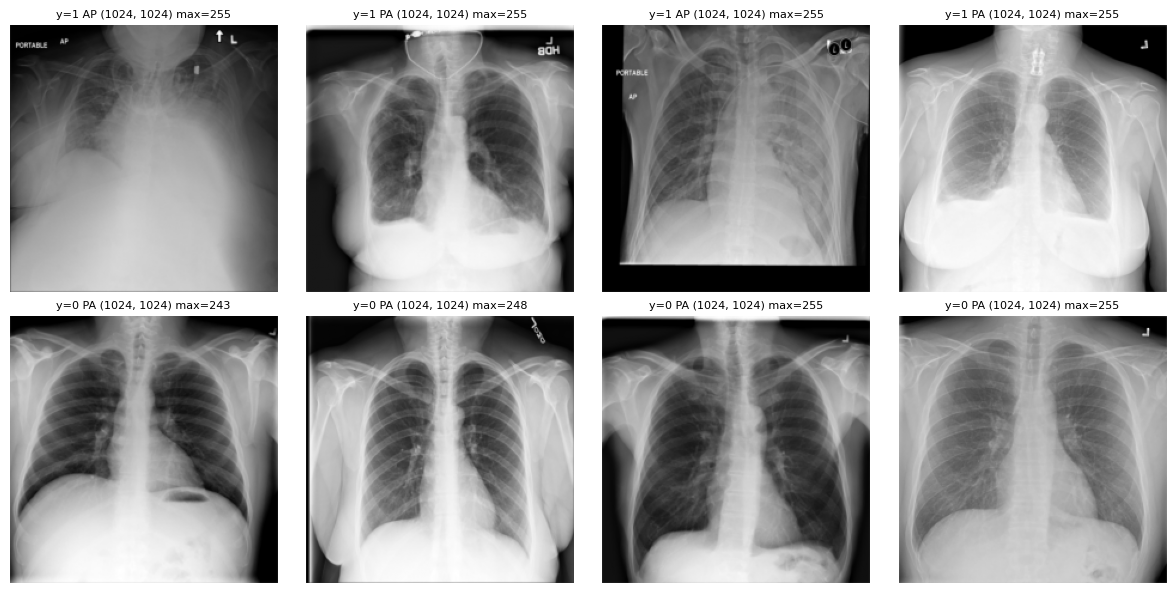

In [9]:
# Visual check of what the DenseNet actually receives (saved for inspection)
import matplotlib.pyplot as plt, torchxrayvision as xrv, torchvision, skimage.io
tfm = torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(), xrv.datasets.XRayResizer(224)])
ex = rand.groupby("label").head(4)
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for a, (_, r) in zip(ax.ravel(), ex.iterrows()):
    img = skimage.io.imread(img_paths[r["Image Index"]])
    raw_shape, raw_max = img.shape, img.max()
    if img.ndim == 3: img = img[..., :3].mean(2)
    x = tfm(xrv.utils.normalize(img, 255 if img.max() <= 255 else 65535)[None])[0]
    a.imshow(x, cmap="gray"); a.axis("off")
    a.set_title(f"y={r['label']} {r['View Position']} {raw_shape} max={raw_max}", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/preprocessed_examples.png", dpi=80); plt.show()

## 6. Reliance estimates (primary: R_dir)

In [10]:
rows, results = [], {}
for name, cache in scores.items():
    tag = name.split("/")[-1]
    for subset in (["all", "vlm"] if name.startswith("xrv") else ["vlm"]):
        s = samp if subset == "all" else samp[samp["vlm"]]
        s = s[s[cols].apply(lambda r: all(k in cache for k in r), axis=1)].copy()
        for c in ["a", "f", "s1", "s"]:
            s[f"p_{c}"] = s[f"img_{c}"].map(lambda k: cache[k][0])
        for scale in ["prob", "logit"]:
            r = item_quantities(s, scale=scale)
            ov, by_dir, sign_p, _ = summarize(r, B=2000, seed=SEED)
            results[(tag, subset, scale)] = r
            row = dict(model=tag, anchors=subset, scale=scale, n_patients=r["patient"].nunique(), sign_test_p=sign_p)
            for q in ["R_dir", "D_flip", "D_ctrl", "R"]:
                row[q] = ov.loc[q, "estimate"]; row[q + "_lo"] = ov.loc[q, "ci_low"]; row[q + "_hi"] = ov.loc[q, "ci_high"]
            row["p_R_dir<=0"] = ov.loc["R_dir", "p_one_sided"]
            for d, v in by_dir.items():
                row["R_dir " + d] = v.loc["R_dir", "estimate"]
            rows.append(row)
        results[(tag, subset, "prob")].to_csv(f"{OUT}/items03_{FINDING}_{tag}_{subset}.csv", index=False)
summary = pd.DataFrame(rows); summary.to_csv(f"{OUT}/summary03_{FINDING}.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(summary.round(4))

,model,anchors,scale,n_patients,sign_test_p,R_dir,R_dir_lo,R_dir_hi,D_flip,D_flip_lo,D_flip_hi,D_ctrl,D_ctrl_lo,D_ctrl_hi,R,R_lo,R_hi,p_R_dir<=0,R_dir absent->present,R_dir present->absent
0,xrv-densenet121-res224-chex,all,prob,1445,0.0000,0.0626,0.0415,0.0819,0.0909,0.0752,0.1051,0.0283,0.0149,0.0420,0.0338,0.0203,0.0469,0.0000,0.0511,0.0749
1,xrv-densenet121-res224-chex,all,logit,1445,0.0000,0.3783,0.2523,0.5035,0.5626,0.4669,0.6539,0.1843,0.0968,0.2672,0.1957,0.1155,0.2732,0.0000,0.2894,0.4742
2,xrv-densenet121-res224-chex,vlm,prob,800,0.0001,0.0707,0.0432,0.0972,0.0929,0.0730,0.1125,0.0222,0.0045,0.0406,0.0384,0.0213,0.0566,0.0000,0.0623,0.0791
3,xrv-densenet121-res224-chex,vlm,logit,800,0.0008,0.4302,0.2642,0.5949,0.5884,0.4633,0.7086,0.1582,0.0426,0.2787,0.2015,0.0951,0.3065,0.0000,0.3600,0.5004
4,Qwen2.5-VL-7B-Instruct,vlm,prob,800,0.2739,0.0018,-0.0029,0.0066,0.0017,-0.0016,0.0053,-0.0000,-0.0031,0.0030,0.0012,-0.0021,0.0043,0.2145,0.0036,-0.0000
5,Qwen2.5-VL-7B-Instruct,vlm,logit,800,0.2509,0.0419,-0.0678,0.1556,0.0823,0.0086,0.1603,0.0404,-0.0344,0.1142,0.0244,-0.0370,0.0851,0.2200,0.0962,-0.0124
6,medgemma-4b-it,vlm,prob,800,0.0000,0.1498,0.1045,0.1942,0.1932,0.1593,0.2246,0.0434,0.0123,0.0740,0.0783,0.0397,0.1142,0.0000,0.1412,0.1583
7,medgemma-4b-it,vlm,logit,800,0.0000,2.7516,1.9808,3.5099,3.6216,3.0436,4.1628,0.8699,0.3322,1.3862,1.5203,0.8954,2.1297,0.0000,2.6876,2.8157


## 7. Paired comparisons on R_dir (shared VLM anchors, log-odds scale)

In [11]:
keys = [k for k in results if k[1] == "vlm" and k[2] == "logit"]
comp = []
for i in range(len(keys)):
    for j in range(i + 1, len(keys)):
        d = paired_difference(results[keys[i]], results[keys[j]], col="R_dir", seed=SEED)
        comp.append(dict(model_1=keys[i][0], model_2=keys[j][0], **d))
comp = pd.DataFrame(comp)
if len(comp):
    p = comp["p_boot"].to_numpy(); o = np.argsort(p); m = len(p)
    adj = np.minimum.accumulate((p[o] * m / np.arange(1, m + 1))[::-1])[::-1]
    comp["p_fdr"] = np.empty(m); comp.loc[o, "p_fdr"] = np.minimum(adj, 1)
    comp.to_csv(f"{OUT}/paired03_{FINDING}.csv", index=False); display(comp.round(4))

,model_1,model_2,estimate,ci_low,ci_high,p_boot,n_patients,p_fdr
0,xrv-densenet121-res224-chex,Qwen2.5-VL-7B-Instruct,0.3883,0.2091,0.5640,0.0,800,0.0
1,xrv-densenet121-res224-chex,medgemma-4b-it,-2.3214,-3.0202,-1.5891,0.0,800,0.0
2,Qwen2.5-VL-7B-Instruct,medgemma-4b-it,-2.7098,-3.4545,-1.9240,0.0,800,0.0


## 8. Reading the results
1. **Diagnostic first (step 5).** DenseNet AUC on random images well above its AUC on flip images: the text-mined flips are noisy and every R_dir is attenuated - the clean CheXTemporal pairs become essential. Similar AUCs (~0.63 on both): suspect preprocessing - look at `preprocessed_examples.png`.
2. **R_dir is the primary result.** The positive control should be > 0 with a tighter CI than in notebook 02 (n ~ 1,500). VLMs: R_dir near 0 with tight CIs means no reliance on the effusion evidence.
3. **D_ctrl** shows how much drift the time-matched control removes.
4. Asymmetry between the two directions points to answer bias.

**Send back:** zip of `/kaggle/working` (summary03, diagnostic03, paired03, items03, triples03, random03, scores03, preprocessed_examples.png) and the full text of any `FAILED` traceback.